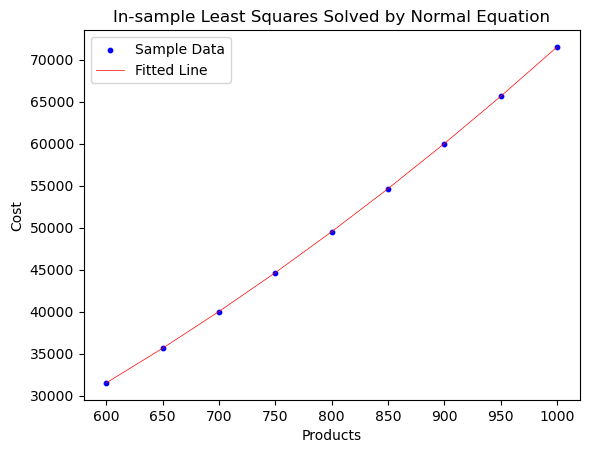

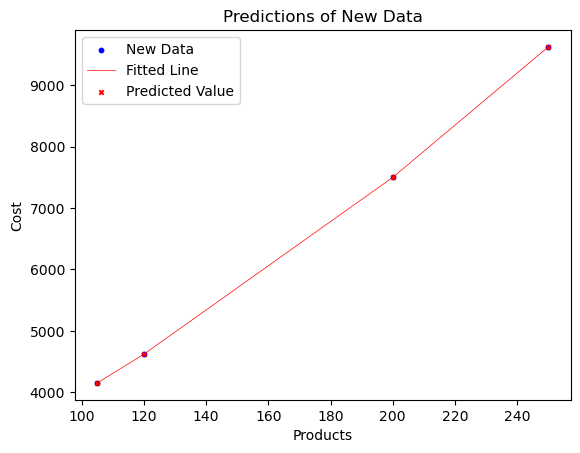

Estimated Beta  [1.49989514e+03 2.00001800e+01 4.99999437e-02]
True Costs of New Data  [4151.42640523 4620.04001572 7500.0978738  9625.22408932]
Predicted Costs of New Data  [4151.16342691 4619.91593762 7499.92890039 9624.93663632]


In [2]:
# Question 1 (a)

import numpy as np
from numpy.linalg import inv
import matplotlib.pyplot as plt

# Setups for the least squares model
x = np.array([600, 650, 700, 750, 800, 850, 900, 950, 1000])
y = np.array([31499.99, 35624.92, 40000.10, 44624.98, 49499.92, 54625.13, 59999.97, 65624.94, 71500.07])

X = np.column_stack((np.ones(x.shape[0]), x, x**2))

# Calculating the estimated beta based on the normal equation
Xt = X.transpose()
beta = inv(Xt.dot(X)).dot(Xt.dot(y))

# Making predictions for new data
x_new = np.array([105, 120, 200, 250])
X_new = np.column_stack((np.ones(x_new.shape[0]), x_new, x_new**2))
y_new_fitted = X_new.dot(beta)

# Generate the true costs for the new data
sigma = 0.1
np.random.seed(0)
epsilon = np.random.normal(0, sigma, x_new.size)
y_new = 1500 + 20*x_new + 0.05*x_new**2 + epsilon

# Plot the in-sample predictions
plt.scatter(x, y, color='blue', label='Sample Data', s=10)
plt.plot(x, X.dot(beta), color='red', label='Fitted Line', linewidth = 0.5)
plt.xlabel('Products')
plt.ylabel('Cost')
plt.title('In-sample Least Squares Solved by Normal Equation')
plt.legend()
plt.show()

# Plot the predictions on the new data
plt.scatter(x_new, y_new, color='blue', label='New Data', s=10)
plt.plot(x_new, X_new.dot(beta), color='red', label='Fitted Line', linewidth = 0.5)
plt.scatter(x_new, X_new.dot(beta), color='red', label='Predicted Value', s=10, marker = "x")
plt.xlabel('Products')
plt.ylabel('Cost')
plt.title('Predictions of New Data')
plt.legend()
plt.show()

print("Estimated Beta ", beta)
print("True Costs of New Data ", y_new)
print("Predicted Costs of New Data ", y_new_fitted)

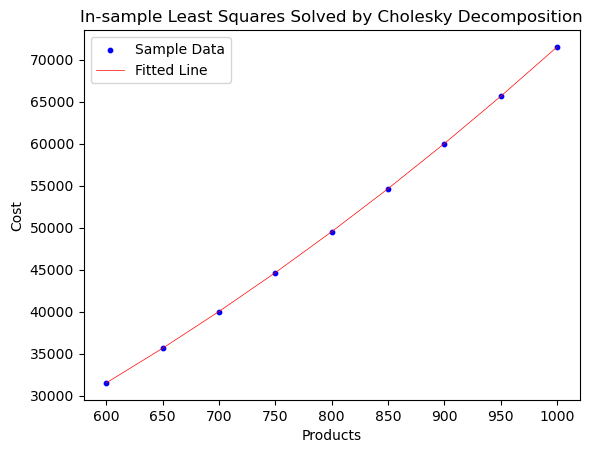

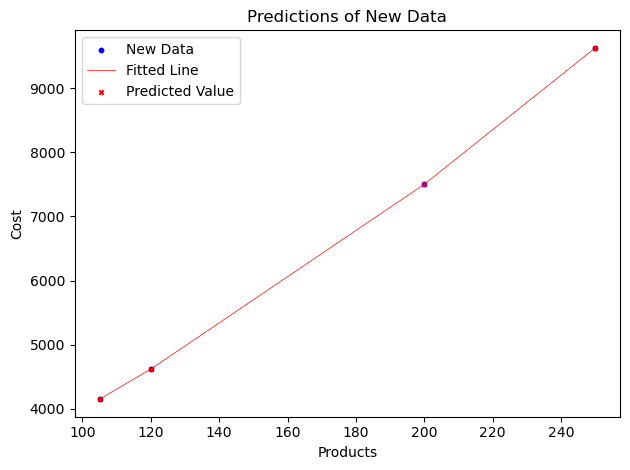

Estimated Beta  [1.49989514e+03 2.00001800e+01 4.99999437e-02]
True Costs of New Data  [4151.42640523 4620.04001572 7500.0978738  9625.22408932]
Predicted Costs of New Data  [4151.16342697 4619.91593769 7499.92890045 9624.93663638]


In [3]:
# Question 1 (b)
import numpy as np
from numpy.linalg import cholesky, inv
import matplotlib.pyplot as plt

# Setups for the least squares model
x = np.array([600, 650, 700, 750, 800, 850, 900, 950, 1000])
y = np.array([31499.99, 35624.92, 40000.10, 44624.98, 49499.92, 54625.13, 59999.97, 65624.94, 71500.07])

X = np.column_stack((np.ones(x.shape[0]), x, x**2))

# Calculating the estimated beta using Cholesky decomposition
Xt = X.transpose()
XtX = Xt.dot(X)
L = cholesky(XtX)

y_temp = inv(L).dot(Xt.dot(y))
beta = inv(L.T).dot(y_temp)

# Making predictions for new data
x_new = np.array([105, 120, 200, 250])
X_new = np.column_stack((np.ones(x_new.shape[0]), x_new, x_new**2))
y_new_fitted = X_new.dot(beta)

# Generate the true costs for the new data
sigma = 0.1
np.random.seed(0)
epsilon = np.random.normal(0, sigma, x_new.size)
y_new = 1500 + 20*x_new + 0.05*x_new**2 + epsilon

# Plot the in-sample predictions
plt.scatter(x, y, color='blue', label='Sample Data', s=10)
plt.plot(x, X.dot(beta), color='red', label='Fitted Line', linewidth = 0.5)
plt.xlabel('Products')
plt.ylabel('Cost')
plt.title('In-sample Least Squares Solved by Cholesky Decomposition')
plt.legend()
plt.show()

# Plot the predictions on the new data
plt.scatter(x_new, y_new, color='blue', label='New Data', s=10)
plt.plot(x_new, X_new.dot(beta), color='red', label='Fitted Line', linewidth = 0.5)
plt.scatter(x_new, y_new_fitted, color='red', label='Predicted Value', s=10, marker = "x")
plt.xlabel('Products')
plt.ylabel('Cost')
plt.title('Predictions of New Data')
plt.legend()
plt.tight_layout()
plt.show()

print("Estimated Beta ", beta)
print("True Costs of New Data ", y_new)
print("Predicted Costs of New Data ", y_new_fitted)

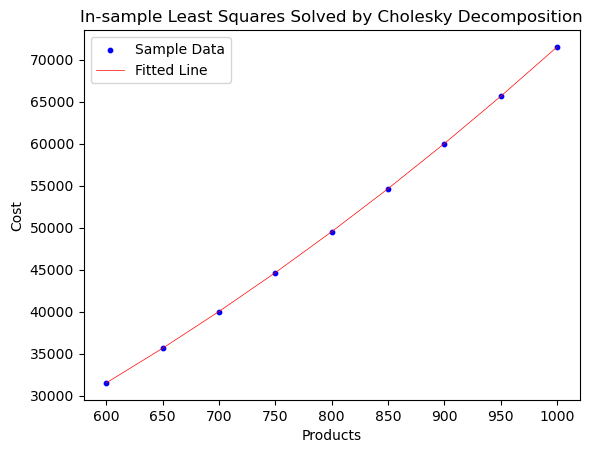

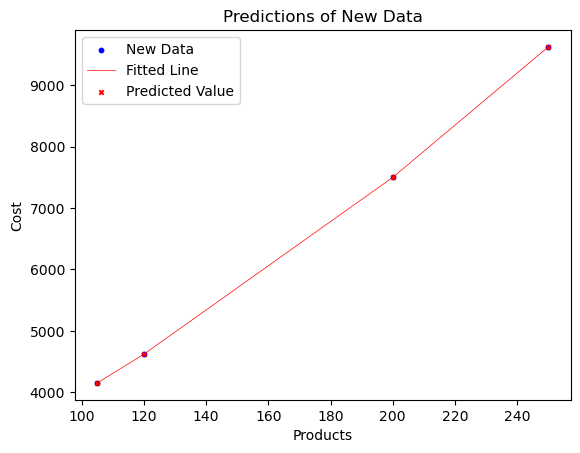

Estimated Beta  [1.49989514e+03 2.00001800e+01 4.99999437e-02]
True Costs of New Data  [4151.42640523 4620.04001572 7500.0978738  9625.22408932]
Predicted Costs of New Data  [4151.16342693 4619.91593765 7499.92890042 9624.93663635]


In [4]:
# Question 1 (c)

from sklearn.linear_model import LinearRegression

# Setups for the least squares model
x = np.array([600, 650, 700, 750, 800, 850, 900, 950, 1000])
y = np.array([31499.99, 35624.92, 40000.10, 44624.98, 49499.92, 54625.13, 59999.97, 65624.94, 71500.07])

X = np.column_stack((np.ones(x.shape[0]), x, x**2))

# Fit the model
model = LinearRegression().fit(X, y)

# Predictions for new data
x_new = np.array([105, 120, 200, 250])
X_new = np.column_stack((np.ones(x_new.shape[0]), x_new, x_new**2))
y_new_fitted = model.predict(X_new)

# Generate the true costs for the new data
sigma = 0.1
np.random.seed(0)
epsilon = np.random.normal(0, sigma, x_new.size)
y_new = 1500 + 20*x_new + 0.05*x_new**2 + epsilon

# Extract Coefficients
beta = model.coef_
beta[0] = model.intercept_ 

# Plot the in-sample predictions
plt.scatter(x, y, color='blue', label='Sample Data', s=10)
plt.plot(x, X.dot(beta), color='red', label='Fitted Line', linewidth = 0.5)
plt.xlabel('Products')
plt.ylabel('Cost')
plt.title('In-sample Least Squares Solved by Cholesky Decomposition')
plt.legend()
plt.show()

# Plot the predictions on the new data
plt.scatter(x_new, y_new, color='blue', label='New Data', s=10)
plt.plot(x_new, X_new.dot(beta), color='red', label='Fitted Line', linewidth = 0.5)
plt.scatter(x_new, y_new_fitted, color='red', label='Predicted Value', s=10, marker = "x")
plt.xlabel('Products')
plt.ylabel('Cost')
plt.title('Predictions of New Data')
plt.legend()
plt.show()

print("Estimated Beta ", beta)
print("True Costs of New Data ", y_new)
print("Predicted Costs of New Data ", y_new_fitted)

In [5]:
# Question 2 (c)

import numpy as np

n = 10  
d = 8   

# Generate x and y
np.random.seed(0)

X = 5 + 0.2 * np.random.randn(n, d)

j_plus_1 = np.arange(2, d + 2)  # Generates (j+1) in the formula

np.random.seed(0)
epsilon = 0.5 * np.random.randn(n)

y = 1 + X @ j_plus_1 + epsilon

# Regression setups
X_with_intercept = np.hstack([np.ones((n, 1)), X])

# Case 1
w_case1 = np.ones(n)
W_case1 = np.diag(w_case1)

beta_star_case1 = np.linalg.inv(X_with_intercept.T @ W_case1 @ X_with_intercept) @ X_with_intercept.T @ W_case1 @ y

# Case 2
np.random.seed(0)
w_case2 = np.random.rand(n)
W_case2 = np.diag(w_case2)

beta_star_case2 = np.linalg.inv(X_with_intercept.T @ W_case2 @ X_with_intercept) @ X_with_intercept.T @ W_case2 @ y

print("Estimated Beta for Case 1 ", beta_star_case1)
print("Estimated Beta for Case 2 ", beta_star_case2)

Estimated Beta for Case 1  [-4.70856382  1.54868769  1.88626927  4.96345567  4.04236175  7.21824253
  6.89242972 10.04650009  8.62692323]
Estimated Beta for Case 2  [-3.2828988   1.61564274  1.66176714  5.20899146  4.09241914  7.13014009
  6.79929674  9.86312437  8.56335706]


In [1]:
# Question 4 (a)

# Modeling Setups
years = np.array([1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2019])
popl = np.array([5.957, 6.322, 6.657, 7.185, 7.748, 8.655, 9.459, 10.03, 10.49])

# Evaluate the function value F_t
def Fval(x, y, beta):
    return beta[0]*np.exp(beta[1]*x) - y

# Evaluate the Jacobian J_t of F
def Jac(x, beta):
    return np.column_stack((np.exp(beta[1]*x), beta[0]*x*np.exp(beta[1]*x)))

# Gauss-Newton scheme
from numpy.linalg import pinv, norm

def GN(Fx, Jac, x, y, beta0, maxiter = 100, tol = 1e-3):
    bet = np.array(beta0)
    err = 0
    for t in range(maxiter):
        Ft = Fx(x, y, bet)
        Jt = Jac(x, bet)
        St = pinv(Jt.T @ Jt)
        yt = Jt.T @ Ft
        dt = St @ yt
        bet = bet - dt
        err = norm(Ft)
        if err <= tol:
            print(f">>> Convergence achieved at iteration: {t}")
            break
    return bet, err, t

# Call the Gauss-Newton solver.

beta0 = [5, 0.01] # initial guess

beta_best, err, n_it = GN(Fval, Jac, years, popl, beta0)

print("Parameters:", beta_best, "\nError: ", err, "\nNumber of Iterations: ", n_it)

NameError: name 'np' is not defined

Parameters:  [3.03943181e-13 1.54453862e-02]


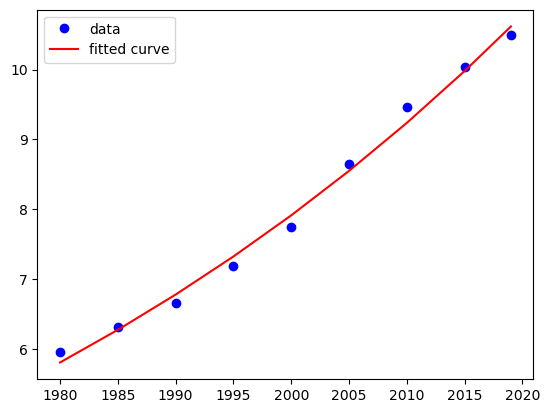

In [6]:
# Question 4 (b)

from scipy.optimize import curve_fit

# Modeling Setups
years = np.array([1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2019])
popl = np.array([5.957, 6.322, 6.657, 7.185, 7.748, 8.655, 9.459, 10.03, 10.49])

def popl_model(t, P_0, beta1):
    return P_0 * np.exp(beta1 * t)

# Solve the problem using scipy's curve_fit

guess = [5, 0.01] # initial guess

params, params_cov = curve_fit(popl_model, years, popl, guess)

# Plots


print("Parameters: ", params)

plt.plot(years, popl, "bo", label= "data")
plt.plot(years, popl_model(years, params[0], params[1]), "r-", label= "fitted curve")
plt.legend()
plt.show()

In [7]:
years_new = np.array([2007, 2017, 2025, 2030])
popl_new_predicted = popl_model(years_new, *params) # Use estimated parameters obtained from the curve_fit 

# Comparison for year 2007 and 2017
actual_popl_new_07_17 = np.array([9.048, 10.27]) 
popl_new_predicted_07_17 = popl_new_predicted[0:1]

ratio = (actual_popl_new_07_17 - popl_new_predicted_07_17) / actual_popl_new_07_17

print("Predictions for 2007, 2017, 2025, and 2030 ", popl_new_predicted)

print("Prediction Error Ratio for 2007 and 2017 ", ratio)

Predictions for 2007, 2017, 2025, and 2030  [ 8.81940556 10.29242649 11.64610073 12.58113354]
Prediction Error Ratio for 2007 and 2017  [0.02526464 0.14124581]
